# Project 1 ? Celebrity Detection
## Milestone 4: Integrated Pipeline & Final Deliverables

**IE 7615** ? Project 1, Milestone 4

**David Fung**

This milestone integrates the Milestone 1 ResNet50 classifier with the Milestone 3 YOLOv8 detector into a single end-to-end pipeline. The system accepts an input image, detects all celebrity faces, identifies each one, and returns annotated results with bounding boxes, identity labels, and confidence scores. A final results gallery is curated, and the repository is prepared for submission.

This notebook includes a baseline 5-class model and an improved 13-class model. The training scripts below can be re-run if needed, but the trained `.keras` models should already exist:

- `python train_classifier.py`
- `python train_classifier_improved.py`

The gallery scripts can also be run separately, but are incorporated into this notebook:

- `python generate_gallery.py`
- `python generate_gallery_improved.py`

All four scripts are required for this notebook.

`celebrity_pipeline.py` and `celebrity_pipeline_improved.py` are used for CLI testing and demo on new images to ascertain the performance of the trained models. The training scripts must be run first.

The Milestone 3 YOLOv8 detector was retrained on the combined dataset (`data/yolo_combined/`), which includes both the synthetic 3?3 grid images and the single-celebrity images from `data/class_images/`. The integrated pipeline therefore uses the same 3-tier decision logic as the CLI pipeline:

1. **YOLO primary** ? if detector confidence is ? `YOLO_THRESH` and the class is one of the target IDs, YOLO's label is accepted directly.
2. **Classifier fallback** ? otherwise the face crop is passed to ResNet50; if confidence is ? `ID_THRESH`, the classifier label is accepted.
3. **Detector fallback** ? otherwise the YOLO class label is kept.

Very low-confidence boxes (< `MIN_KEEP_CONF`) are dropped, and class-agnostic NMS (IoU > 0.5) collapses duplicate boxes on the same face.


## Task 1: Environment & Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
import cv2

from tensorflow.keras.applications.resnet50 import preprocess_input 
from keras.src.utils import python_utils
python_utils.preprocess_input = preprocess_input

import ultralytics
from ultralytics import YOLO
import torch

import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

print(f"Ultralytics: {ultralytics.__version__}")
print(f"PyTorch: {torch.__version__}")
print(f"TensorFlow: {tf.__version__}")


Ultralytics: 8.4.163
PyTorch: 2.14.0+cpu
TensorFlow: 2.19.0


In [2]:
# PROJECT CONSTANTS
GLOBAL_SEED = 42
np.random.seed(GLOBAL_SEED)
tf.keras.utils.set_random_seed(GLOBAL_SEED)

SCRIPT_DIR = os.path.abspath(os.getcwd())
ROOT = os.path.abspath(os.path.join(SCRIPT_DIR, ".."))

# Base Model
CLASSIFIER_PATH = os.path.join(SCRIPT_DIR, "models", "resnet50_classifier.keras")
CLASS_NAMES_5 = ["7", "797", "2619", "4428", "7007"]

# Improved Model
CLASSIFIER_IMP_PATH = os.path.join(SCRIPT_DIR, "models", "resnet50_classifier_improved.keras")
CLASS_NAMES_13 = ["3", "7", "797", "1212", "2336", "2619", "2970", "4422", "4428", "5695", "7007", "8335", "10002"]

TARGET_IDS = {"7", "797", "2619", "4428", "7007"}

NUM_CLASSES_DET = 13
NUM_CLASSES_CLS = 5
# CONF is the detector threshold; MIN_KEEP_CONF removes boxes far below that threshold.
# ID_THRESH gates whether the ResNet50 identity is accepted.
# YOLO_THRESH gates whether YOLO's own identity is accepted directly.
CONF = 0.1
MIN_KEEP_CONF = 0.05
ID_THRESH = 0.5
YOLO_THRESH = 0.3
IMGSZ = 640

print(f"Classifier: {CLASSIFIER_PATH}")
print(f"Classifier classes: {CLASS_NAMES_5}")
print(f"Target IDs: {sorted(TARGET_IDS)}")


Classifier: h:\Education\Northeastern\MS_DAE\IE7615\Project_1\Milestone_4\models\resnet50_classifier.keras
Classifier classes: ['7', '797', '2619', '4428', '7007']
Target IDs: ['2619', '4428', '7', '7007', '797']


In [3]:
# Run model training scripts scripts - if not already, please note that this will take some time.

# !python train_classifier.py
# !python train_classifier_improved.py

## Task 2: Load Models

In [4]:
# Load YOLOv8 detection model (from Milestone 3)
DET_PATH = os.path.join(ROOT, "Milestone_3", "runs", "detect",
                        "celebrity_detection", "yolov8n_finetune", "weights", "best.pt")
det_model = YOLO(DET_PATH)
det_names = det_model.names
print(f"Detector classes ({NUM_CLASSES_DET}): {list(det_names.values())}")

Detector classes (13): ['3', '7', '797', '1212', '2336', '2619', '2970', '4422', '4428', '5695', '7007', '8335', '10002']


In [5]:
# Load ResNet50 classification model (from Milestone 4 training)
cls_model = tf.keras.models.load_model(CLASSIFIER_PATH, compile=False, safe_mode=False)
cls_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness_1             │ (None, 224, 224, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,113,541 (91.99 MB)

 Trainable params: 4,991,493 (19.04 MB)

 Non-trainable params: 19,122,048 (72.94 MB)

In [6]:
# Load Imrpvoed ResNet50 classification model (from Milestone 4 training)
cls_model_imp = tf.keras.models.load_model(CLASSIFIER_IMP_PATH, compile=False, safe_mode=False)
cls_model_imp.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness_1             │ (None, 224, 224, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 13)             │         3,341 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,773,517 (94.50 MB)

 Trainable params: 5,650,445 (21.55 MB)

 Non-trainable params: 19,123,072 (72.95 MB)

## Task 3: Integrated Pipeline

The functions below implement the same 3-tier logic described above:

- **YOLO primary:** `det_conf >= YOLO_THRESH` and class in `TARGET_IDS` ? accept YOLO identity.
- **Classifier fallback:** crop the face and run ResNet50; accept the classifier label if `top_prob >= ID_THRESH`.
- **Detector fallback:** otherwise keep the YOLO class label.

Before classification, boxes with confidence below `MIN_KEEP_CONF` are removed, and class-agnostic NMS (IoU > 0.5) is applied to suppress duplicate detections of the same face.


In [7]:
def compute_iou(box_a, box_b):
    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area_a = max(0, box_a[2] - box_a[0]) * max(0, box_a[3] - box_a[1])
    area_b = max(0, box_b[2] - box_b[0]) * max(0, box_b[3] - box_b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0


def nms_detections(detections, iou_thresh=0.5):
    if not detections:
        return detections
    order = sorted(range(len(detections)),
                   key=lambda i: detections[i].get("confidence", 0.0),
                   reverse=True)
    keep = []
    while order:
        i = order.pop(0)
        keep.append(i)
        order = [j for j in order
                 if compute_iou(detections[i]["bbox"], detections[j]["bbox"]) <= iou_thresh]
    return [detections[i] for i in keep]


def run_pipeline(image_path, conf=CONF, imgsz=IMGSZ, id_thresh=ID_THRESH,
                 yolo_thresh=YOLO_THRESH, min_keep_conf=MIN_KEEP_CONF):
    """Run the full celebrity-identification pipeline on a single image.

    1. YOLOv8 detects faces (13-class) with confidence.
    2. Very low-confidence boxes are dropped, then class-agnostic NMS collapses
       duplicate boxes on the same face.
    3. If YOLO is confident (>= yolo_thresh) and the class is one of the target
       IDs, its identity is used directly (source = "yolo").
    4. Otherwise the crop is passed to the ResNet50 (5-class) identifier. If the
       identifier is confident (>= id_thresh) its label is used (source =
       "classifier"); otherwise the detector label is kept (source = "detector").
    """
    import cv2
    target_indices = {i for i, n in det_names.items() if n in TARGET_IDS}
    img = det_model(source=image_path, conf=conf, imgsz=imgsz, verbose=False)[0]
    boxes = img.boxes
    full_img = img.orig_img

    raw = []
    for i in range(len(boxes)):
        x1, y1, x2, y2 = map(int, boxes.xyxy[i].tolist())
        cls_idx = int(boxes.cls[i].item())
        det_label = str(det_names.get(cls_idx, cls_idx))
        det_conf = float(boxes.conf[i].item())
        raw.append({"bbox": [x1, y1, x2, y2], "cls_idx": cls_idx,
                    "det_label": det_label, "confidence": det_conf,
                    "det_conf": det_conf})

    raw = [d for d in raw if d["confidence"] >= min_keep_conf]
    raw = nms_detections(raw, iou_thresh=0.5)

    results = []
    for det in raw:
        x1, y1, x2, y2 = det["bbox"]
        if det["confidence"] >= yolo_thresh and det["cls_idx"] in target_indices:
            results.append({"label": det["det_label"], "confidence": det["confidence"],
                            "bbox": [x1, y1, x2, y2], "source": "yolo",
                            "is_target": True})
            continue
        face_arr = full_img[y1:y2, x1:x2]
        if face_arr is not None and face_arr.size > 0:
            resized = cv2.resize(face_arr, (224, 224))
            arr = resized.astype(np.float32)[np.newaxis, ...]
            probs = cls_model.predict(arr, verbose=0)[0]
            top_idx = int(np.argmax(probs))
            top_prob = float(probs[top_idx])
            if top_prob >= id_thresh:
                results.append({"label": CLASS_NAMES_5[top_idx],
                                "confidence": top_prob, "bbox": [x1, y1, x2, y2],
                                "source": "classifier",
                                "is_target": det["det_label"] in TARGET_IDS})
                continue
        results.append({"label": det["det_label"], "confidence": det["confidence"],
                        "bbox": [x1, y1, x2, y2], "source": "detector",
                        "is_target": det["det_label"] in TARGET_IDS})
    return results


In [8]:
# For improved model

def run_pipeline_imp(image_path, conf=CONF, imgsz=IMGSZ, id_thresh=ID_THRESH,
                     yolo_thresh=YOLO_THRESH, min_keep_conf=MIN_KEEP_CONF):
    """Same 3-tier pipeline as run_pipeline, but uses the improved 13-class
    ResNet50 model when YOLO's identity is not accepted directly."""
    import cv2
    target_indices = {i for i, n in det_names.items() if n in TARGET_IDS}
    img = det_model(source=image_path, conf=conf, imgsz=imgsz, verbose=False)[0]
    boxes = img.boxes
    full_img = img.orig_img

    raw = []
    for i in range(len(boxes)):
        x1, y1, x2, y2 = map(int, boxes.xyxy[i].tolist())
        cls_idx = int(boxes.cls[i].item())
        det_label = str(det_names.get(cls_idx, cls_idx))
        det_conf = float(boxes.conf[i].item())
        raw.append({"bbox": [x1, y1, x2, y2], "cls_idx": cls_idx,
                    "det_label": det_label, "confidence": det_conf,
                    "det_conf": det_conf})

    raw = [d for d in raw if d["confidence"] >= min_keep_conf]
    raw = nms_detections(raw, iou_thresh=0.5)

    results = []
    for det in raw:
        x1, y1, x2, y2 = det["bbox"]
        if det["confidence"] >= yolo_thresh and det["cls_idx"] in target_indices:
            results.append({"label": det["det_label"], "confidence": det["confidence"],
                            "bbox": [x1, y1, x2, y2], "source": "yolo",
                            "is_target": True})
            continue
        face_arr = full_img[y1:y2, x1:x2]
        if face_arr is not None and face_arr.size > 0:
            resized = cv2.resize(face_arr, (224, 224))
            arr = resized.astype(np.float32)[np.newaxis, ...]
            probs = cls_model_imp.predict(arr, verbose=0)[0]
            top_idx = int(np.argmax(probs))
            top_prob = float(probs[top_idx])
            if top_prob >= id_thresh:
                results.append({"label": CLASS_NAMES_13[top_idx],
                                "confidence": top_prob, "bbox": [x1, y1, x2, y2],
                                "source": "classifier",
                                "is_target": det["det_label"] in TARGET_IDS})
                continue
        results.append({"label": det["det_label"], "confidence": det["confidence"],
                        "bbox": [x1, y1, x2, y2], "source": "detector",
                        "is_target": det["det_label"] in TARGET_IDS})
    return results


## Task 4: Run Pipeline on Test Images

In [9]:
test_dir = os.path.join(ROOT, "data", "synthetic_grid", "images", "test")
test_files = sorted(glob.glob(os.path.join(test_dir, "*.jpg")))

print(f"Test images: {len(test_files)}")
all_results = {}
for f in test_files:
    res = run_pipeline(f)
    all_results[f] = res
    n_yolo = sum(1 for r in res if r["source"] == "yolo")
    n_cls = sum(1 for r in res if r["source"] == "classifier")
    n_det = sum(1 for r in res if r["source"] == "detector")
    print(f"  {os.path.basename(f)}: {len(res)} faces (Baseline: {n_yolo} yolo, {n_cls} classified, {n_det} detector)")
    for r in res:
        mark = " *" if r["label"] not in TARGET_IDS else ""
        print(f"     {r['label']:>5}  conf={r['confidence']:.4f}  [{r['source']}]{mark}")


Test images: 3
  grid_0000.jpg: 9 faces (Baseline: 2 yolo, 7 classified, 0 detector)
      2619  conf=0.6667  [classifier]
         7  conf=0.8149  [classifier]
       797  conf=0.9981  [yolo]
      7007  conf=0.5385  [classifier]
      7007  conf=0.8837  [classifier]
      7007  conf=0.5951  [classifier]
      2619  conf=0.9775  [yolo]
         7  conf=0.7250  [classifier]
      4428  conf=0.5216  [classifier]
  grid_0005.jpg: 9 faces (Baseline: 2 yolo, 6 classified, 1 detector)
         7  conf=0.7070  [classifier]
      7007  conf=0.9944  [classifier]
      2619  conf=0.9154  [classifier]
       797  conf=0.9898  [yolo]
       797  conf=0.5815  [classifier]
         7  conf=0.9365  [classifier]
      2619  conf=0.9753  [yolo]
      7007  conf=0.9604  [classifier]
      8335  conf=0.6854  [detector] *
  grid_0017.jpg: 9 faces (Baseline: 2 yolo, 7 classified, 0 detector)
         7  conf=0.7236  [classifier]
      7007  conf=0.7031  [classifier]
      7007  conf=0.8341  [classifier]
 

In [10]:
# Run with Improved model

print(f"Test images: {len(test_files)}")
all_results_imp = {}
for f in test_files:
    res = run_pipeline_imp(f)
    all_results_imp[f] = res
    n_yolo = sum(1 for r in res if r["source"] == "yolo")
    n_cls = sum(1 for r in res if r["source"] == "classifier")
    n_det = sum(1 for r in res if r["source"] == "detector")
    print(f"  {os.path.basename(f)}: {len(res)} faces (Improved: {n_yolo} yolo, {n_cls} classified, {n_det} detector)")
    for r in res:
        mark = " *" if r["label"] not in TARGET_IDS else ""
        print(f"     {r['label']:>5}  conf={r['confidence']:.4f}  [{r['source']}]{mark}")


Test images: 3
  grid_0000.jpg: 9 faces (Improved: 2 yolo, 6 classified, 1 detector)
      8335  conf=0.9759  [classifier] *
      1212  conf=0.9829  [classifier] *
       797  conf=0.9981  [yolo]
      2970  conf=0.9955  [detector] *
     10002  conf=0.9092  [classifier] *
         3  conf=0.9997  [classifier] *
      2619  conf=0.9775  [yolo]
      4422  conf=0.6251  [classifier] *
      7007  conf=0.6234  [classifier]
  grid_0005.jpg: 9 faces (Improved: 2 yolo, 7 classified, 0 detector)
      1212  conf=0.9936  [classifier] *
      4422  conf=0.7838  [classifier] *
      2619  conf=0.6006  [classifier]
       797  conf=0.9898  [yolo]
         3  conf=0.9207  [classifier] *
      1212  conf=0.8326  [classifier] *
      2619  conf=0.9753  [yolo]
     10002  conf=0.9269  [classifier] *
      2619  conf=0.7062  [classifier]
  grid_0017.jpg: 9 faces (Improved: 2 yolo, 7 classified, 0 detector)
      1212  conf=0.9684  [classifier] *
      4422  conf=0.9022  [classifier] *
      7007  con

## Task 5: Results Gallery (Test Set Only)

The gallery is generated **exclusively from the 3 synthetic test images** (`data/synthetic_grid/images/test/`).

**Color legend:**  
- **Green** = TP (detected + classified correctly)  
- **Orange** = Misclassified (detected, IoU > 0.5, wrong class)  
- **Red** = FP (no GT match, IoU < 0.5)  
- **Blue border** = FN (missed GT)

In [11]:
# Run gallery generation generation scripts

!python generate_gallery.py
!python generate_gallery_improved.py

Loading classifier (5-class baseline)...
Loading YOLOv8: h:\Education\Northeastern\MS_DAE\IE7615\Project_1\Milestone_3\runs\detect\celebrity_detection\yolov8n_finetune\weights\best.pt

  TEST SET

  [Test] Processing 3 images...
    grid_0000.jpg: 9 faces -> 2 correct, 7 incorrect, 0 missed (FN)
    grid_0005.jpg: 9 faces -> 2 correct, 7 incorrect, 0 missed (FN)
    grid_0017.jpg: 9 faces -> 2 correct, 7 incorrect, 0 missed (FN)
    Saved 3 annotated images + captions to: h:\Education\Northeastern\MS_DAE\IE7615\Project_1\Milestone_4\gallery

  TRAIN SET

  [Train] Processing 14 images...
    grid_0002.jpg: 9 faces -> 4 correct, 5 incorrect, 0 missed (FN)
    grid_0003.jpg: 9 faces -> 3 correct, 6 incorrect, 0 missed (FN)
    grid_0004.jpg: 9 faces -> 4 correct, 5 incorrect, 0 missed (FN)
    grid_0006.jpg: 9 faces -> 4 correct, 5 incorrect, 0 missed (FN)
    grid_0007.jpg: 9 faces -> 3 correct, 6 incorrect, 0 missed (FN)
    grid_0009.jpg: 9 faces -> 4 correct, 5 incorrect, 0 missed (F

Loading classifier (13-class improved)...
Loading YOLOv8: h:\Education\Northeastern\MS_DAE\IE7615\Project_1\Milestone_3\runs\detect\celebrity_detection\yolov8n_finetune\weights\best.pt

  TEST SET

  [Test] Processing 3 images...
    grid_0000.jpg: 9 faces -> 8 correct, 1 incorrect, 0 missed (FN)
    grid_0005.jpg: 9 faces -> 6 correct, 3 incorrect, 0 missed (FN)
    grid_0017.jpg: 9 faces -> 6 correct, 3 incorrect, 0 missed (FN)
    Saved 3 annotated images + captions to: h:\Education\Northeastern\MS_DAE\IE7615\Project_1\Milestone_4\gallery

  TRAIN SET

  [Train] Processing 14 images...
    grid_0002.jpg: 9 faces -> 7 correct, 2 incorrect, 0 missed (FN)
    grid_0003.jpg: 9 faces -> 8 correct, 1 incorrect, 0 missed (FN)
    grid_0004.jpg: 9 faces -> 7 correct, 2 incorrect, 0 missed (FN)
    grid_0006.jpg: 9 faces -> 7 correct, 2 incorrect, 0 missed (FN)
    grid_0007.jpg: 9 faces -> 6 correct, 3 incorrect, 0 missed (FN)
    grid_0009.jpg: 9 faces -> 8 correct, 1 incorrect, 0 missed (

In [12]:
# Display results table

gallery_dir = os.path.join(SCRIPT_DIR, "gallery")

def parse_captions(path):
    """Parse captions.md to extract per-image stats."""
    results = []
    current = None
    with open(path, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line.startswith('## grid_'):
                if current:
                    results.append(current)
                current = {'image': line[3:]}
            elif 'Correct:' in line and 'Incorrect:' in line and current:
                import re
                m = re.search(r'Correct: (\d+).*?Incorrect: (\d+).*?Missed \(FN\): (\d+).*?GT total: (\d+)', line)
                if m:
                    current['tp'] = int(m.group(1))
                    current['mis'] = int(m.group(2))
                    current['fn'] = int(m.group(3))
                    current['gt'] = int(m.group(4))
                    current['fp'] = int(m.group(4)) - int(m.group(1)) - int(m.group(2))
                    if current['fp'] < 0:
                        current['fp'] = 0
    if current:
        results.append(current)
    return results

def print_results_table(captions_path, model_name):
    results = parse_captions(captions_path)
    print(f"\n### {model_name} — Test Set Results\n")
    print(f"{'Image':<20} {'TP':>4} {'Mis':>4} {'FP':>4} {'FN':>4} {'GT':>4} {'System Acc':>12} {'F1':>8}")
    print(f"{'-'*20} {'-'*4} {'-'*4} {'-'*4} {'-'*4} {'-'*4} {'-'*12} {'-'*8}")
    tot_tp = tot_mis = tot_fp = tot_fn = tot_gt = 0
    for r in results:
        acc = f"{100*r['tp']/(r['tp']+r['mis']):.1f}%" if (r['tp']+r['mis'])>0 else 'N/A'
        f1 = f"{100*2*r['tp']/(2*r['tp']+r['fp']+r['fn']):.1f}%" 
        print(f"{r['image']:<20} {r['tp']:>4} {r['mis']:>4} {r['fp']:>4} {r['fn']:>4} {r['gt']:>4} {acc:>12} {f1:>8}")
        tot_tp += r['tp']; tot_mis += r['mis']; tot_fp += r['fp']
        tot_fn += r['fn']; tot_gt += r['gt']
    acc_total = f"{100*tot_tp/(tot_tp+tot_mis):.1f}%" if (tot_tp+tot_mis)>0 else 'N/A'
    f1_total = f"{100*2*tot_tp/((2*tot_tp)+tot_fp+tot_fn):.1f}%" 
    print(f"{'-'*20} {'-'*4} {'-'*4} {'-'*4} {'-'*4} {'-'*4} {'-'*12} {'-'*8}")
    print(f"{'TOTAL':<20} {tot_tp:>4} {tot_mis:>4} {tot_fp:>4} {tot_fn:>4} {tot_gt:>4} {acc_total:>12} {f1_total:>8}")

# Print both tables
cap_base = os.path.join(gallery_dir, "captions.md")
cap_imp = os.path.join(gallery_dir, "captions_improved.md")
if os.path.exists(cap_base):
    print_results_table(cap_base, "Baseline (5-class)")
if os.path.exists(cap_imp):
    print_results_table(cap_imp, "Improved (13-class)")


### Baseline (5-class) — Test Set Results

Image                  TP  Mis   FP   FN   GT   System Acc       F1
-------------------- ---- ---- ---- ---- ---- ------------ --------
grid_0000.jpg           2    7    0    0    9        22.2%   100.0%
grid_0005.jpg           2    7    0    0    9        22.2%   100.0%
grid_0017.jpg           2    7    0    0    9        22.2%   100.0%
-------------------- ---- ---- ---- ---- ---- ------------ --------
TOTAL                   6   21    0    0   27        22.2%   100.0%

### Improved (13-class) — Test Set Results

Image                  TP  Mis   FP   FN   GT   System Acc       F1
-------------------- ---- ---- ---- ---- ---- ------------ --------
grid_0000.jpg           8    1    0    0    9        88.9%   100.0%
grid_0005.jpg           6    3    0    0    9        66.7%   100.0%
grid_0017.jpg           6    3    0    0    9        66.7%   100.0%
-------------------- ---- ---- ---- ---- ---- ------------ --------
TOTAL                  20  

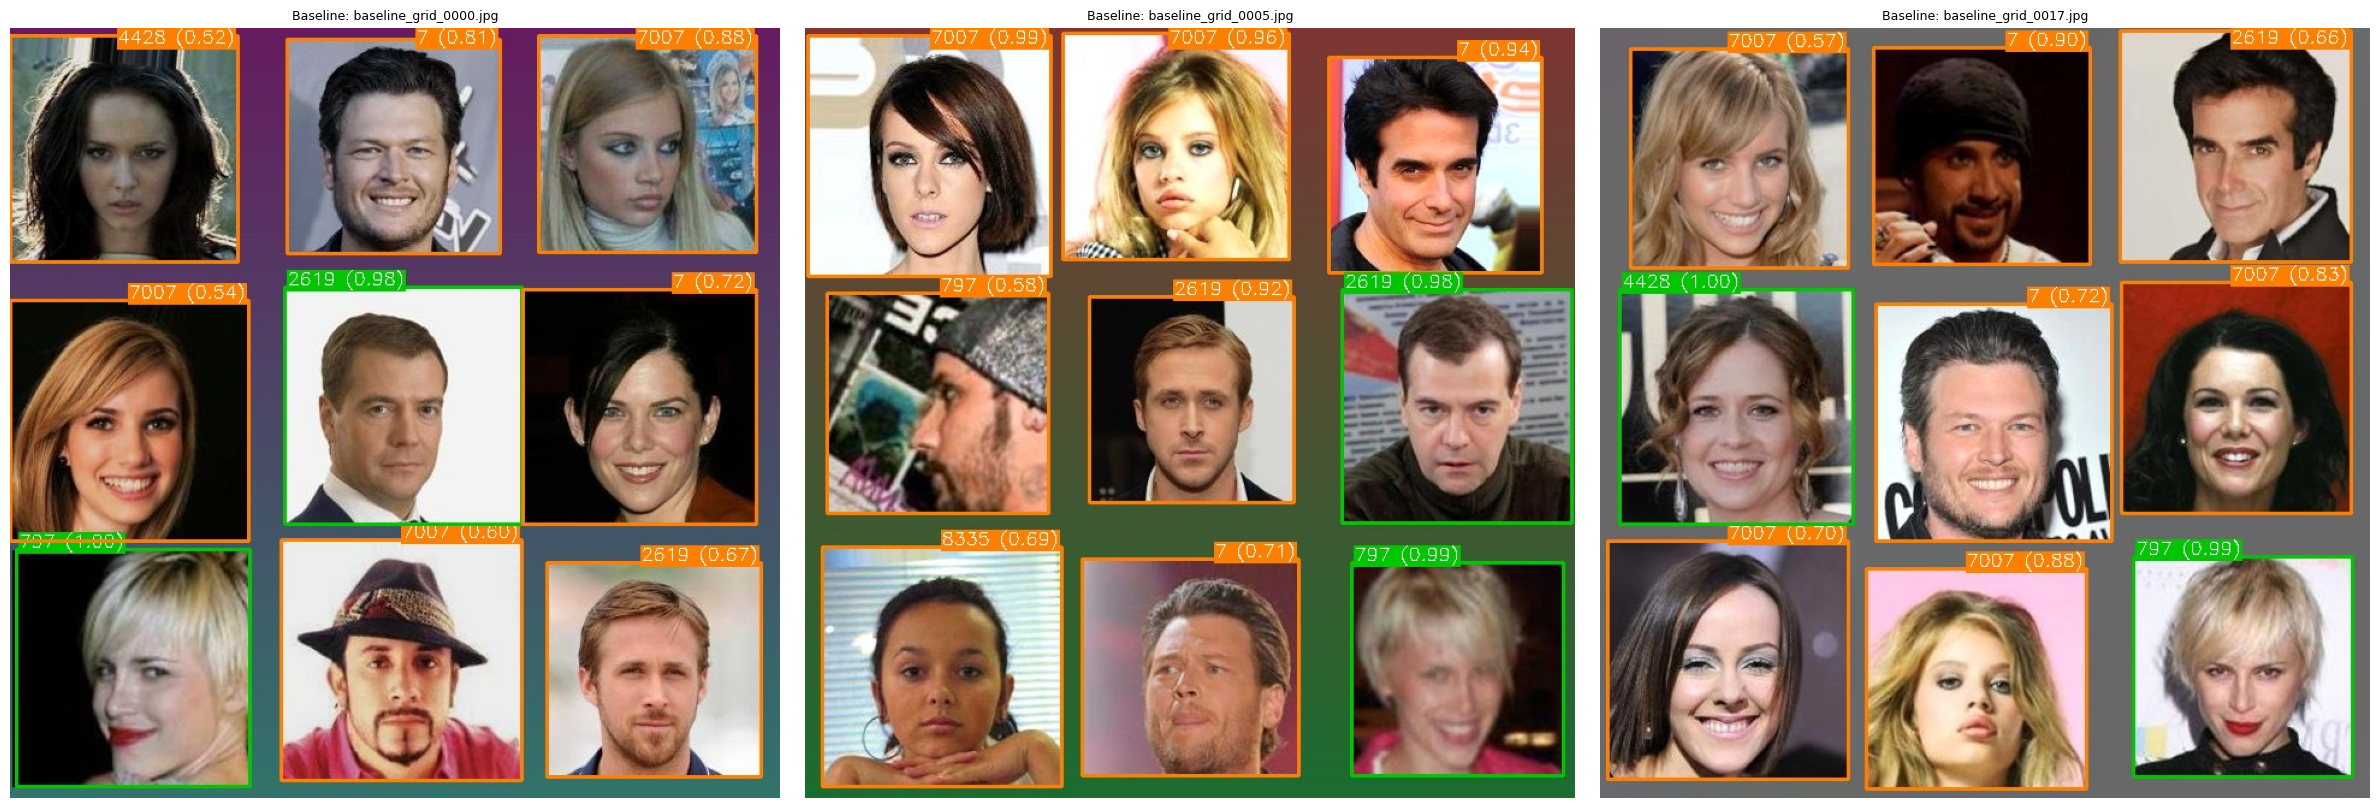

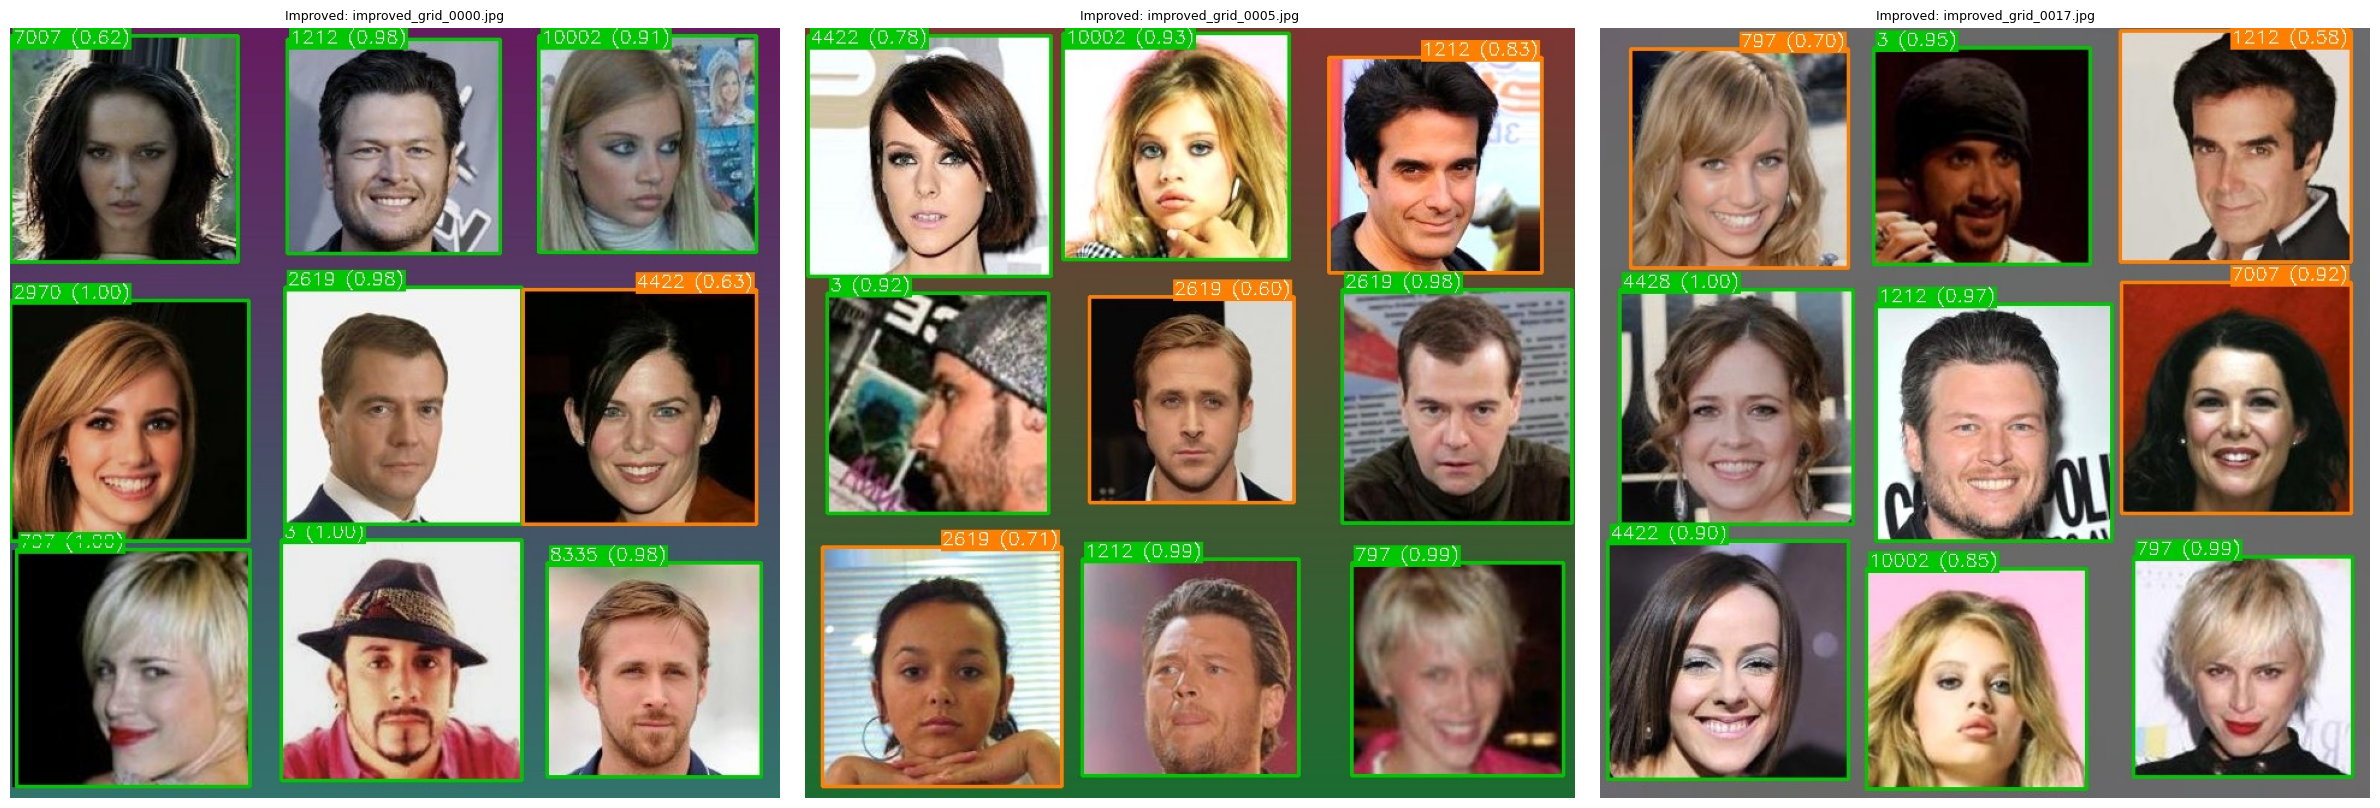

In [13]:
# Display the annotated gallery images

baseline_imgs = sorted(glob.glob(os.path.join(gallery_dir, "baseline_grid_*.jpg")))
if baseline_imgs:
    fig, axes = plt.subplots(1, len(baseline_imgs), figsize=(8*len(baseline_imgs), 8))
    if len(baseline_imgs) == 1:
        axes = [axes]
    for i, ip in enumerate(baseline_imgs):
        img = cv2.imread(ip)
        axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[i].set_title(f"Baseline: {os.path.basename(ip)}", fontsize=9)
        axes[i].axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(SCRIPT_DIR, "pipeline_summary.png"), dpi=150, bbox_inches="tight")
    plt.show()

# Display the 3 annotated gallery images (improved)
improved_imgs = sorted(glob.glob(os.path.join(gallery_dir, "improved_grid_*.jpg")))
if improved_imgs:
    fig, axes = plt.subplots(1, len(improved_imgs), figsize=(8*len(improved_imgs), 8))
    if len(improved_imgs) == 1:
        axes = [axes]
    for i, ip in enumerate(improved_imgs):
        img = cv2.imread(ip)
        axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[i].set_title(f"Improved: {os.path.basename(ip)}", fontsize=9)
        axes[i].axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(SCRIPT_DIR, "pipeline_summary_imp.png"), dpi=150, bbox_inches="tight")
    plt.show()